# T11 · Association Rules (Transaction data · Frequent itemsets · Apriori / FP-Growth · Rules · Support / Confidence / Lift)

**ใช้เมื่อโจทย์ถาม:** market basket / "สินค้าอะไรถูกซื้อด้วยกัน" · เตรียมข้อมูล transaction (ตะกร้า → ตาราง True/False) ·
discretize ตัวเลขก่อนหากฎ · frequent itemsets (min support) · Apriori ทีละขั้น (C1 → L1 → C2 → L2 …) · สร้างกฎ (min confidence) ·
ตีความ support / confidence / lift · กฎที่ทำนาย item เป้าหมาย (เช่น `pep=YES`) · ผลของการเปลี่ยน min support / min confidence

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** — `DATA_PATH`, `FORMAT`, `ID_COL`, `MIN_SUPPORT`, `MIN_CONFIDENCE` (+ `BINS` ถ้าเป็นตารางที่มีตัวเลข) |
| 2 | Run All → §2 สินค้าขายดี · §3 frequent itemsets · §4 กฎ + ประโยคตีความ · §6 ผลของ min support |
| 3 | โจทย์ให้คำนวณมือ (ข้อมูล 5–10 ตะกร้า) → §7 แก้ `SMALL_TRANSACTIONS` |

**รูปแบบข้อมูลที่รองรับ (`FORMAT`)**
| FORMAT | หน้าตาไฟล์ | ตัวอย่าง |
|---|---|---|
| `"basket"` | 1 บรรทัด = 1 ตะกร้า คั่นด้วย comma (จำนวนไม่เท่ากัน, ไม่มีหัวตาราง) | `milk,bread,eggs` |
| `"onehot"` | 1 แถว = 1 ตะกร้า · 1 คอลัมน์ = 1 สินค้า ค่า 0/1, T/F, Y/N | BeautyCo (`Trans.` = id) |
| `"long"` | 2 คอลัมน์: รหัสตะกร้า + สินค้า (1 แถว = 1 สินค้าในตะกร้า) | `tid,item` |
| `"table"` | ตาราง attribute ทั่วไป (หมวดหมู่ + ตัวเลข) → แปลงเป็น item `attr=value` | bank-data (`pep=YES`) |
| `"auto"` | เดาให้ (basket / onehot / table) — `long` ต้องระบุเอง | |

> สูตร: **support(A→B)** = P(A∪B) · **confidence** = support(A∪B) / support(A) = P(B|A) · **lift** = confidence / support(B)
> lift > 1 = ซื้อด้วยกันบ่อยกว่าบังเอิญ (สัมพันธ์บวก) · = 1 อิสระกัน · < 1 สัมพันธ์ลบ (ทดแทนกัน)

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../practice/data/p9_groceries_baskets.csv"
#   ตัวอย่างอื่น: "../../W10/BeautyCo_68.xls" (FORMAT="onehot", ID_COL="Trans.")
#               "../mock_lab/mock3_cluster_assoc/data/bank-data.csv" (FORMAT="table", ID_COL="id", BINS ด้านล่าง)
FORMAT    = "auto"           # "basket" | "onehot" | "long" | "table" | "auto"
ID_COL    = None             # คอลัมน์รหัสตะกร้า/ลูกค้า (ไม่ใช่สินค้า) เช่น "Trans." · None = ไม่มี
DROP_COLS = []               # คอลัมน์ที่ไม่เอามาหากฎ (เช่น region, sex ที่ไม่ให้ข้อมูล)
LONG_TID, LONG_ITEM = "tid", "item"   # ใช้เมื่อ FORMAT = "long"
BASKET_SEP = ","             # ตัวคั่นสินค้าในไฟล์ basket
# FORMAT = "table": คอลัมน์ตัวเลขต้อง discretize ก่อน
BINS       = {}              # {"age": 3, "income": 3} = แบ่ง 3 ช่วง · {"children": [-1, 0, 2, 10]} = กำหนดขอบเอง
BIN_METHOD = "frequency"     # "frequency" (equal frequency, เหมาะกับข้อมูลเบ้) | "width" (equal width)
BIN_LABELS = None            # เช่น ["LOW", "MID", "HIGH"] · None = ใช้ช่วงตัวเลข

ALGO           = "apriori"   # "apriori" | "fpgrowth" (ผลเหมือนกัน fpgrowth เร็วกว่า · RapidMiner ใช้ FP-Growth)
MIN_SUPPORT    = 0.02        # สัดส่วน (0.02 = 2% ของตะกร้า) · โจทย์ให้เป็น "จำนวนครั้ง" → หารด้วยจำนวนตะกร้า
MIN_CONFIDENCE = 0.30
MAX_LEN        = None        # ขนาด itemset สูงสุด (None = ไม่จำกัด)
TARGET_ITEM    = None        # สนใจกฎที่ "ทำนาย" item นี้ เช่น "pep=YES" / "whole milk" · None = ทุกกฎ
SORT_BY        = "lift"      # "lift" | "confidence" | "support"
TOP_N          = 10
RULE_TO_EXPLAIN = None       # (["root vegetables"], ["other vegetables"]) = คำนวณมือกฎนี้ · None = ใช้กฎอันดับ 1
SEED = 42
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        for enc in ["utf-8-sig", "cp874", "latin1"]:      # utf-8 (ตัด BOM) → ภาษาไทยจาก Excel (cp874) → อื่น ๆ
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
        if df.shape[1] == 1 and ";" in str(df.columns[0]):  # ไฟล์คั่นด้วย ; แต่ตั้ง CSV_SEP = ","
            df = pd.read_csv(path, sep=";", encoding=enc)
            print("ℹ️ ไฟล์นี้คั่นด้วย ';' → อ่านใหม่ด้วย sep=';'")
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def fix_col(df, col, kind="any", i=0):
    """คอลัมน์ที่ตั้งไว้ใน ✏️ ไม่มีในข้อมูลนี้ → เลือกคอลัมน์ชนิดเดียวกันให้ชั่วคราว (Run All ไม่หยุด) — ควรแก้ ✏️ ให้ตรงโจทย์
    kind: "num" = ตัวเลขต่อเนื่อง · "cat" = หมวดหมู่ (ค่าไม่เกิน 20 แบบ) · "any" """
    if col is None or col in df.columns:
        return col
    skip = {ID_COL}
    nums = [c for c in num_cols(df) if c not in skip]
    if kind == "num":
        pool = [c for c in nums if df[c].nunique() > 10] or nums
    elif kind == "cat":
        few = [c for c in df.columns if c not in skip and df[c].nunique() <= 20]
        pool = [c for c in few if c not in nums] + [c for c in few if c in nums]
    else:
        pool = [c for c in df.columns if c not in skip]
    new = pool[min(i, len(pool) - 1)] if pool else None
    print(f"⚠️ ไม่มีคอลัมน์ {col!r} ในข้อมูลนี้ → ใช้ {new!r} แทนชั่วคราว (แก้บรรทัด ✏️ ให้ตรงโจทย์)")
    return new


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": float(mean_absolute_error(y_true, y_pred)), "MSE": float(mse), "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_true, y_pred))}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §0 เครื่องมือ association (mlxtend ถ้ามี · ถ้าไม่มีใช้ Apriori ที่เขียนเองด้านล่าง — ผลเหมือนกัน)
ไม่ต้องแก้ cell นี้ · ติดตั้ง mlxtend: `pip install mlxtend`

In [3]:
from itertools import combinations
try:
    from mlxtend.frequent_patterns import apriori as _mx_apriori, fpgrowth as _mx_fpgrowth, association_rules as _mx_rules
    HAS_MLXTEND = True
except ImportError:
    HAS_MLXTEND = False
print("mlxtend:", "✅ มี" if HAS_MLXTEND else "❌ ไม่มี → ใช้ Apriori ที่เขียนเอง (ผลเหมือนกัน)")


def my_apriori(items, min_support, max_len=None, verbose=False):
    """Apriori แบบตำรา: Ck (join L(k-1) + prune ด้วย subset) → นับ support → Lk"""
    M = items.values.astype(bool); n = len(M); cols = list(items.columns)
    sup = M.mean(axis=0)
    L = {(i,): s for i, s in enumerate(sup) if s >= min_support}
    out, k = dict(L), 1
    if verbose:
        print(f"C1: {len(cols)} candidates → L1: {len(L)} frequent")
    while L and (max_len is None or k < max_len):
        k += 1
        prev = sorted(L)
        prev_set = set(prev)
        cands = []
        for a in range(len(prev)):
            for b in range(a + 1, len(prev)):
                if prev[a][:-1] != prev[b][:-1]:
                    break
                c = prev[a] + (prev[b][-1],)
                if all(s in prev_set for s in combinations(c, k - 1)):     # prune: ทุก subset ต้อง frequent
                    cands.append(c)
        L = {}
        for c in cands:
            s = M[:, list(c)].all(axis=1).mean()
            if s >= min_support:
                L[c] = s
        if verbose:
            print(f"C{k}: {len(cands)} candidates (หลัง prune) → L{k}: {len(L)} frequent")
        out.update(L)
    return pd.DataFrame({"support": list(out.values()),
                         "itemsets": [frozenset(cols[i] for i in c) for c in out]})


def my_rules(freq, min_confidence):
    sup = {s: v for s, v in zip(freq["itemsets"], freq["support"])}
    rows = []
    for iset, s in sup.items():
        if len(iset) < 2:
            continue
        for r in range(1, len(iset)):
            for ante in combinations(sorted(iset), r):
                A = frozenset(ante); C = iset - A
                conf = s / sup[A]
                if conf >= min_confidence:
                    rows.append({"antecedents": A, "consequents": C, "antecedent support": sup[A],
                                 "consequent support": sup[C], "support": s, "confidence": conf,
                                 "lift": conf / sup[C], "leverage": s - sup[A] * sup[C],
                                 "conviction": np.inf if conf == 1 else (1 - sup[C]) / (1 - conf)})
    return pd.DataFrame(rows)


def frequent_itemsets(items, min_support, algo=None, max_len=None):
    algo = ALGO if algo is None else algo
    if HAS_MLXTEND:
        f = (_mx_fpgrowth if algo == "fpgrowth" else _mx_apriori)(items.astype(bool), min_support=min_support,
                                                                   use_colnames=True, max_len=max_len)
    else:
        f = my_apriori(items, min_support, max_len)
    f["size"] = f["itemsets"].apply(len)
    return f.sort_values(["size", "support"], ascending=[True, False]).reset_index(drop=True)


def make_rules(freq, min_confidence, n_trans):
    if len(freq) == 0 or freq["size"].max() < 2:
        return pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift"])
    if HAS_MLXTEND:
        try:
            r = _mx_rules(freq.drop(columns="size"), num_itemsets=n_trans, metric="confidence", min_threshold=min_confidence)
        except TypeError:                     # mlxtend รุ่นเก่าไม่มี num_itemsets
            r = _mx_rules(freq.drop(columns="size"), metric="confidence", min_threshold=min_confidence)
    else:
        r = my_rules(freq, min_confidence)
    if len(r) == 0:
        return r
    return r.sort_values([SORT_BY, "confidence"], ascending=False).reset_index(drop=True)


def iset_str(s):
    return "{" + ", ".join(sorted(map(str, s))) + "}"


def pretty(rules, n=None):
    """ตารางกฎอ่านง่าย: A → B"""
    t = rules.copy()
    t.insert(0, "rule", [f"{iset_str(a)} → {iset_str(c)}" for a, c in zip(t["antecedents"], t["consequents"])])
    keep = ["rule", "antecedent support", "consequent support", "support", "confidence", "lift"] + \
           [c for c in ["leverage", "conviction"] if c in t]
    t = t[[c for c in keep if c in t]]
    return t.head(n) if n else t


def explain_rule(A, C, items):
    """นับมือจากตาราง item → support / confidence / lift ของกฎ A → C + ประโยคตีความ"""
    A, C = list(A), list(C)
    n = len(items)
    nA = int(items[A].all(axis=1).sum()); nC = int(items[C].all(axis=1).sum()); nAC = int(items[A + C].all(axis=1).sum())
    sup, conf = nAC / n, (nAC / nA if nA else float("nan"))
    lift = conf / (nC / n)
    print(f"กฎ {iset_str(A)} → {iset_str(C)}  (จำนวนตะกร้าทั้งหมด N = {n})")
    print(f"  count(A) = {nA} · count(C) = {nC} · count(A∪C) = {nAC}")
    print(f"  support    = count(A∪C)/N        = {nAC}/{n} = {sup:.4f}")
    print(f"  confidence = count(A∪C)/count(A) = {nAC}/{nA} = {conf:.4f}")
    print(f"  lift       = confidence/support(C) = {conf:.4f}/{nC / n:.4f} = {lift:.4f}")
    kind = ("สัมพันธ์เชิงบวก (ซื้อด้วยกันบ่อยกว่าบังเอิญ)" if lift > 1.05 else
            "สัมพันธ์เชิงลบ (ซื้อด้วยกันน้อยกว่าบังเอิญ / ทดแทนกัน)" if lift < 0.95 else "เกือบอิสระกัน")
    print(f"✍️ ตะกร้าที่มี {iset_str(A)} และ {iset_str(C)} พร้อมกันมี {sup:.1%} ของทั้งหมด (support) · "
          f"ในตะกร้าที่มี {iset_str(A)} มี {iset_str(C)} ด้วย {conf:.1%} (confidence) · "
          f"ซึ่งเป็น {lift:.2f} เท่าของโอกาสปกติที่ {nC / n:.1%} (lift) → {kind}")
    return {"support": sup, "confidence": conf, "lift": lift}

mlxtend: ✅ มี


## §1 โหลด + แปลงเป็นตาราง transaction (True/False)
ผลลัพธ์ = `items` : 1 แถว = 1 ตะกร้า · 1 คอลัมน์ = 1 item · ค่า True = มีในตะกร้า

In [4]:
def _is_basket_file(path, sep=BASKET_SEP):
    if str(path).lower().endswith((".xls", ".xlsx")):
        return False
    lines = [l for l in open(path, encoding="utf-8-sig").read().splitlines()[:200] if l.strip()]
    return len({l.count(sep) for l in lines}) > 1           # จำนวนช่องไม่เท่ากัน = basket


_TRUE = {"1", "1.0", "true", "t", "y", "yes"}
_FALSE = {"0", "0.0", "false", "f", "n", "no", "nan", ""}


def _is_onehot(df):
    vals = set()
    for c in df.columns:
        vals |= set(df[c].astype(str).str.strip().str.lower().unique())
    return vals <= (_TRUE | _FALSE)


fmt = FORMAT
if fmt == "auto":
    fmt = "basket" if _is_basket_file(DATA_PATH) else None
if fmt == "basket":
    baskets = [[i.strip() for i in l.split(BASKET_SEP) if i.strip()]
               for l in open(DATA_PATH, encoding="utf-8-sig").read().splitlines() if l.strip()]
    all_items = sorted({i for b in baskets for i in b})
    items = pd.DataFrame([[i in set(b) for i in all_items] for b in baskets], columns=all_items)
    print(f"basket: {len(baskets)} ตะกร้า | ตัวอย่าง: {baskets[:2]}")
else:
    raw = load_data(DATA_PATH)
    raw = raw.drop(columns=[c for c in list(DROP_COLS) + [ID_COL] if c and c in raw.columns and (fmt != "long" or c not in (LONG_TID, LONG_ITEM))])
    if fmt is None:
        fmt = "onehot" if _is_onehot(raw) else "table"
    if fmt == "long":
        items = pd.crosstab(raw[LONG_TID], raw[LONG_ITEM]).gt(0)
        items.columns = [str(c) for c in items.columns]
    elif fmt == "onehot":
        items = raw.apply(lambda s: s.astype(str).str.strip().str.lower().isin(_TRUE))
    else:   # table → discretize ตัวเลข → item "attr=value"
        tab = raw.copy()
        for c, b in BINS.items():
            if isinstance(b, int) and BIN_METHOD == "frequency":
                tab[c] = pd.qcut(tab[c], b, labels=BIN_LABELS, duplicates="drop")
            else:
                tab[c] = pd.cut(tab[c], b, labels=BIN_LABELS, include_lowest=True)
            print(f"discretize {c} ({BIN_METHOD if isinstance(b, int) else 'กำหนดขอบเอง'}):", tab[c].value_counts().sort_index().to_dict())
        left_num = [c for c in num_cols(tab) if tab[c].nunique() > 10]
        if left_num:
            print("⚠️ ยังเป็นตัวเลขต่อเนื่อง (ควรใส่ใน BINS):", left_num)
        items = pd.get_dummies(tab.astype(str).replace("nan", np.nan), prefix_sep="=").astype(bool)
print(f"FORMAT = {fmt} → items: {items.shape[0]} transactions × {items.shape[1]} items")
display(items.head())

basket: 9835 ตะกร้า | ตัวอย่าง: [['citrus fruit', 'margarine', 'ready soups', 'semi-finished bread'], ['coffee', 'tropical fruit', 'yogurt']]
FORMAT = basket → items: 9835 transactions × 169 items


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,bottled water,brandy,brown bread,butter,butter milk,cake bar,candles,candy,canned beer,canned fish,canned fruit,canned vegetables,cat food,cereals,chewing gum,chicken,chocolate,...,soda,soft cheese,softener,sound storage medium,soups,sparkling wine,specialty bar,specialty cheese,specialty chocolate,specialty fat,specialty vegetables,spices,spread cheese,sugar,sweet spreads,syrup,tea,tidbits,toilet cleaner,tropical fruit,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False


**✍️ คำตอบ §1:** ข้อมูลเป็น transaction … ตะกร้า × … item · ตัด `…` (id ไม่ซ้ำ → ไม่มีทาง frequent / attribute ที่เกือบคงที่หรือ 50:50 ไม่ให้ข้อมูล) · discretize `…` แบบ equal frequency เพราะ … (ข้อมูลเบ้)

## §2 สำรวจ: จำนวน item ต่อตะกร้า + item ที่พบบ่อย (support ของ 1-itemset)

ตะกร้า 9835 · item 169 · item ต่อตะกร้า: เฉลี่ย 4.41 · median 3 · max 32


,support,count
whole milk,0.2555,2513
other vegetables,0.1935,1903
rolls/buns,0.1839,1809
soda,0.1744,1715
yogurt,0.1395,1372
bottled water,0.1105,1087
root vegetables,0.1090,1072
tropical fruit,0.1049,1032
shopping bags,0.0985,969
sausage,0.0940,924


item ที่ support < MIN_SUPPORT (0.02): 110 จาก 169 → ถูกตัดตั้งแต่รอบแรกของ Apriori


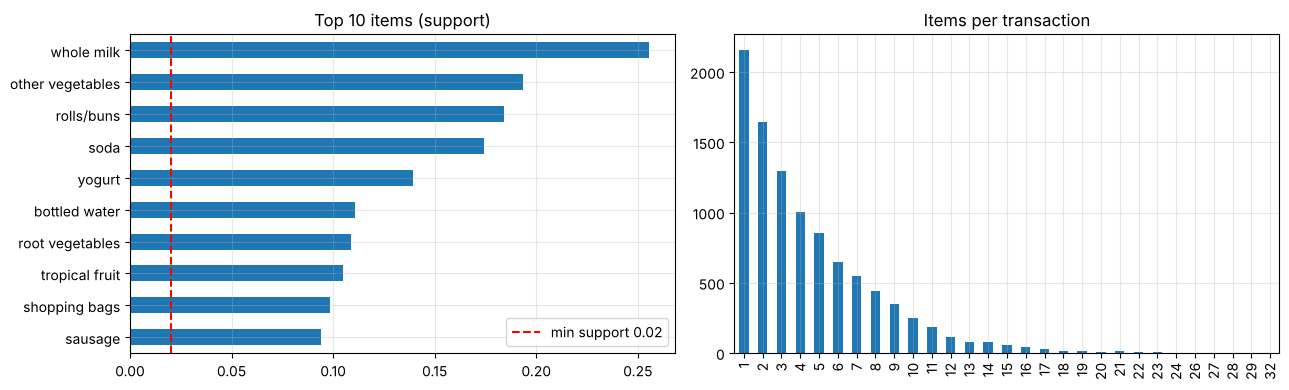

✍️ item ที่พบบ่อยสุดคือ whole milk (support = 0.2555 = 2513 ตะกร้า)


In [5]:
size = items.sum(axis=1)
item_sup = items.mean().sort_values(ascending=False)
print(f"ตะกร้า {len(items)} · item {items.shape[1]} · item ต่อตะกร้า: เฉลี่ย {size.mean():.2f} · median {size.median():.0f} · max {size.max()}")
top = item_sup.head(TOP_N).to_frame("support"); top["count"] = items[top.index].sum().values
display(top.round(4))
print(f"item ที่ support < MIN_SUPPORT ({MIN_SUPPORT}): {(item_sup < MIN_SUPPORT).sum()} จาก {len(item_sup)} → ถูกตัดตั้งแต่รอบแรกของ Apriori")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
item_sup.head(TOP_N)[::-1].plot.barh(ax=ax[0], title=f"Top {TOP_N} items (support)")
ax[0].axvline(MIN_SUPPORT, color="r", ls="--", label=f"min support {MIN_SUPPORT}"); ax[0].legend()
size.value_counts().sort_index().plot.bar(ax=ax[1], title="Items per transaction"); plt.tight_layout(); plt.show()
print(f"✍️ item ที่พบบ่อยสุดคือ {item_sup.index[0]} (support = {item_sup.iloc[0]:.4f} = {int(items[item_sup.index[0]].sum())} ตะกร้า)")

## §3 Frequent itemsets (Apriori / FP-Growth, min support)
**Apriori principle:** ถ้า itemset ไม่ frequent → superset ทุกตัวก็ไม่ frequent → ตัดทิ้งได้ (anti-monotone ของ support)

In [6]:
freq = frequent_itemsets(items, MIN_SUPPORT, ALGO, MAX_LEN)
print(f"{ALGO} min_support = {MIN_SUPPORT} (≥ {int(np.ceil(MIN_SUPPORT * len(items)))} ตะกร้า) → frequent itemsets {len(freq)} ชุด")
print("แยกตามขนาด:", freq["size"].value_counts().sort_index().to_dict())
show_f = freq.assign(itemset=freq["itemsets"].apply(iset_str), count=(freq["support"] * len(items)).round().astype(int))
for k in sorted(freq["size"].unique()):
    print(f"── {k}-itemsets (top {TOP_N}):")
    display(show_f[show_f["size"] == k].sort_values("support", ascending=False)[["itemset", "support", "count"]].head(TOP_N))
# maximal = ไม่มี superset ที่ frequent · closed = ไม่มี superset ที่ support เท่ากัน
sets = list(zip(freq["itemsets"], freq["support"]))
maximal = sum(1 for s, _ in sets if not any(s < t for t, _ in sets))
closed = sum(1 for s, v in sets if not any(s < t and abs(v - w) < 1e-12 for t, w in sets))
print(f"maximal frequent itemsets = {maximal} · closed frequent itemsets = {closed}")

apriori min_support = 0.02 (≥ 197 ตะกร้า) → frequent itemsets 122 ชุด
แยกตามขนาด: {1: 59, 2: 61, 3: 2}
── 1-itemsets (top 10):


,itemset,support,count
0,{whole milk},0.2555,2513
1,{other vegetables},0.1935,1903
2,{rolls/buns},0.1839,1809
3,{soda},0.1744,1715
4,{yogurt},0.1395,1372
5,{bottled water},0.1105,1087
6,{root vegetables},0.1090,1072
7,{tropical fruit},0.1049,1032
8,{shopping bags},0.0985,969
9,{sausage},0.0940,924


── 2-itemsets (top 10):


,itemset,support,count
59,"{other vegetables, whole milk}",0.0748,736
60,"{rolls/buns, whole milk}",0.0566,557
61,"{whole milk, yogurt}",0.0560,551
62,"{root vegetables, whole milk}",0.0489,481
63,"{other vegetables, root vegetables}",0.0474,466
64,"{other vegetables, yogurt}",0.0434,427
65,"{other vegetables, rolls/buns}",0.0426,419
66,"{tropical fruit, whole milk}",0.0423,416
67,"{soda, whole milk}",0.0401,394
68,"{rolls/buns, soda}",0.0383,377


── 3-itemsets (top 10):


,itemset,support,count
120,"{other vegetables, root vegetables, whole milk}",0.0232,228
121,"{other vegetables, whole milk, yogurt}",0.0223,219


maximal frequent itemsets = 91 · closed frequent itemsets = 122


**✍️ คำตอบ §3:** min support … ได้ frequent itemset … ชุด (1-item … · 2-item … · 3-item …) · คู่ที่พบบ่อยสุดคือ {…} support … (… ตะกร้า)

## §4 สร้างกฎ (min confidence) → เรียงตาม lift ⭐
กฎ A → B สร้างจาก frequent itemset ที่มี ≥ 2 item: แบ่งเป็น A (antecedent / LHS) กับ B (consequent / RHS) แล้วเก็บเฉพาะ confidence ≥ min

In [7]:
rules = make_rules(freq, MIN_CONFIDENCE, len(items))
print(f"min_confidence = {MIN_CONFIDENCE} → {len(rules)} rules (เรียงตาม {SORT_BY})")
if len(rules):
    display(pretty(rules, TOP_N).round(4))
    r1 = rules.iloc[0]
    print(f"✍️ กฎอันดับ 1: {iset_str(r1.antecedents)} → {iset_str(r1.consequents)} · support {r1.support:.4f} · "
          f"confidence {r1.confidence:.4f} · lift {r1.lift:.4f}")
    print(f"   = ตะกร้า {r1.support:.1%} มีทั้งสองอย่าง · คนที่ซื้อ {iset_str(r1.antecedents)} ซื้อ {iset_str(r1.consequents)} ด้วย {r1.confidence:.1%} "
          f"· มากกว่าปกติ ({r1['consequent support']:.1%}) {r1.lift:.2f} เท่า → เสนอ: จัดวางใกล้กัน / ทำโปรโมชันคู่ / แนะนำสินค้า (cross-sell)")
    neg = rules[rules["lift"] < 1]
    print(f"กฎที่ lift < 1 (confidence ผ่านแต่สัมพันธ์ลบ — มักเพราะ consequent เป็นของขายดี): {len(neg)} กฎ")
    if len(neg):
        display(pretty(neg.sort_values("lift"), 5).round(4))
else:
    print("⚠️ ไม่มีกฎผ่านเกณฑ์ → ลด MIN_SUPPORT หรือ MIN_CONFIDENCE")

min_confidence = 0.3 → 37 rules (เรียงตาม lift)


,rule,antecedent support,consequent support,support,confidence,lift,leverage,conviction
0,"{other vegetables, whole milk} → {root vegetab...",0.0748,0.1090,0.0232,0.3098,2.8421,0.0150,1.2909
1,"{root vegetables, whole milk} → {other vegetab...",0.0489,0.1935,0.0232,0.4740,2.4498,0.0137,1.5333
2,{root vegetables} → {other vegetables},0.1090,0.1935,0.0474,0.4347,2.2466,0.0263,1.4267
3,{whipped/sour cream} → {other vegetables},0.0717,0.1935,0.0289,0.4028,2.0819,0.0150,1.3506
4,"{whole milk, yogurt} → {other vegetables}",0.0560,0.1935,0.0223,0.3975,2.0541,0.0114,1.3385
5,"{other vegetables, yogurt} → {whole milk}",0.0434,0.2555,0.0223,0.5129,2.0072,0.0112,1.5283
6,{butter} → {whole milk},0.0554,0.2555,0.0276,0.4972,1.9461,0.0134,1.4808
7,{pork} → {other vegetables},0.0577,0.1935,0.0217,0.3757,1.9415,0.0105,1.2918
8,{curd} → {whole milk},0.0533,0.2555,0.0261,0.4905,1.9195,0.0125,1.4611
9,"{other vegetables, root vegetables} → {whole m...",0.0474,0.2555,0.0232,0.4893,1.9148,0.0111,1.4577


✍️ กฎอันดับ 1: {other vegetables, whole milk} → {root vegetables} · support 0.0232 · confidence 0.3098 · lift 2.8421
   = ตะกร้า 2.3% มีทั้งสองอย่าง · คนที่ซื้อ {other vegetables, whole milk} ซื้อ {root vegetables} ด้วย 31.0% · มากกว่าปกติ (10.9%) 2.84 เท่า → เสนอ: จัดวางใกล้กัน / ทำโปรโมชันคู่ / แนะนำสินค้า (cross-sell)
กฎที่ lift < 1 (confidence ผ่านแต่สัมพันธ์ลบ — มักเพราะ consequent เป็นของขายดี): 0 กฎ


In [8]:
# กฎที่ "ทำนาย" item เป้าหมาย (consequent = TARGET_ITEM) — เช่นหาโปรไฟล์ลูกค้าที่ซื้อ pep=YES
if TARGET_ITEM is not None and len(rules):
    tr = rules[rules["consequents"] == frozenset({TARGET_ITEM})].sort_values("lift", ascending=False)
    base = items[TARGET_ITEM].mean() if TARGET_ITEM in items else float("nan")
    print(f"P({TARGET_ITEM}) ทั้งหมด = {base:.4f} · กฎที่ทำนาย {TARGET_ITEM}: {len(tr)} กฎ")
    display(pretty(tr, TOP_N).round(4))
    # กฎที่มี TARGET_ITEM อยู่ฝั่งไหนก็ได้
    anyside = rules[rules.apply(lambda r: TARGET_ITEM in r.antecedents or TARGET_ITEM in r.consequents, axis=1)]
    print(f"กฎที่มี {TARGET_ITEM} อยู่ฝั่งใดฝั่งหนึ่ง: {len(anyside)} กฎ")
else:
    print("TARGET_ITEM = None → ข้าม (ตัวอย่าง TARGET_ITEM = 'pep=YES' หรือ 'whole milk')")

TARGET_ITEM = None → ข้าม (ตัวอย่าง TARGET_ITEM = 'pep=YES' หรือ 'whole milk')


**✍️ คำตอบ §4 (ตีความกฎ 1 ข้อให้ครบ 3 ค่า):** กฎ {…} → {…}
- **support = …** → ตะกร้า …% มีทั้ง … และ … (กฎนี้เกิดบ่อยแค่ไหน / สำคัญแค่ไหนต่อยอดขาย)
- **confidence = …** → ลูกค้าที่ซื้อ … มี …% ที่ซื้อ … ด้วย (ความน่าเชื่อถือของกฎ = P(B|A))
- **lift = …** → มากกว่าโอกาสปกติ … เท่า (> 1 = สัมพันธ์จริง ไม่ใช่เพราะ … ขายดีอยู่แล้ว)
- **ข้อเสนอ:** วางสินค้าใกล้กัน / bundle / แนะนำ … ให้คนที่ซื้อ …
- confidence สูงแต่ lift ≤ 1 = กฎหลอก (consequent ขายดีอยู่แล้ว) → ใช้ lift ประกอบเสมอ

## §5 คำนวณกฎด้วยมือ (นับจากตาราง) — ตรวจสูตร / ตอบโจทย์ "แสดงวิธีคำนวณ" 

In [9]:
if RULE_TO_EXPLAIN is not None:
    A, C = RULE_TO_EXPLAIN
elif len(rules):
    A, C = sorted(rules.iloc[0].antecedents), sorted(rules.iloc[0].consequents)
else:
    A = C = None
if A is not None:
    explain_rule(A, C, items)

กฎ {other vegetables, whole milk} → {root vegetables}  (จำนวนตะกร้าทั้งหมด N = 9835)
  count(A) = 736 · count(C) = 1072 · count(A∪C) = 228
  support    = count(A∪C)/N        = 228/9835 = 0.0232
  confidence = count(A∪C)/count(A) = 228/736 = 0.3098
  lift       = confidence/support(C) = 0.3098/0.1090 = 2.8421
✍️ ตะกร้าที่มี {other vegetables, whole milk} และ {root vegetables} พร้อมกันมี 2.3% ของทั้งหมด (support) · ในตะกร้าที่มี {other vegetables, whole milk} มี {root vegetables} ด้วย 31.0% (confidence) · ซึ่งเป็น 2.84 เท่าของโอกาสปกติที่ 10.9% (lift) → สัมพันธ์เชิงบวก (ซื้อด้วยกันบ่อยกว่าบังเอิญ)


## §6 ผลของการเปลี่ยน min support / min confidence
- min support ↑ → itemset/กฎ **น้อยลง** (เหลือแต่ของขายดี) · ↓ → กฎเยอะ ช้าขึ้น และมีกฎจาก item ที่หายาก
- min confidence ↑ → กฎน้อยลงแต่น่าเชื่อถือขึ้น (ไม่ได้รับประกันว่า lift สูง)

In [10]:
SUP_GRID  = [MIN_SUPPORT / 2, MIN_SUPPORT, MIN_SUPPORT * 2, MIN_SUPPORT * 5]   # ✏️ ค่า min support ที่ลอง
CONF_GRID = [0.2, 0.3, 0.5, 0.7, 0.9]                                            # ✏️ ค่า min confidence ที่ลอง
grid_rows = []
for s in SUP_GRID:
    f = frequent_itemsets(items, s, ALGO, MAX_LEN)
    row = {"min_support": s, "frequent itemsets": len(f), "max size": int(f["size"].max()) if len(f) else 0}
    for c in CONF_GRID:
        row[f"rules (conf≥{c})"] = len(make_rules(f, c, len(items)))
    grid_rows.append(row)
sens = pd.DataFrame(grid_rows); display(sens)
print(f"✍️ เพิ่ม min support จาก {SUP_GRID[0]:g} เป็น {SUP_GRID[-1]:g} → itemset ลดจาก {sens.iloc[0, 1]} เหลือ {sens.iloc[-1, 1]} "
      f"· เพิ่ม min confidence → จำนวนกฎลดลง (ดูแต่ละแถว)")

,min_support,frequent itemsets,max size,rules (conf≥0.2),rules (conf≥0.3),rules (conf≥0.5),rules (conf≥0.7),rules (conf≥0.9)
0,0.0100,333,3,234,125,15,0,0
1,0.0200,122,3,73,37,1,0,0
2,0.0400,41,2,15,7,0,0,0
3,0.1000,8,1,0,0,0,0,0


✍️ เพิ่ม min support จาก 0.01 เป็น 0.1 → itemset ลดจาก 333 เหลือ 8 · เพิ่ม min confidence → จำนวนกฎลดลง (ดูแต่ละแถว)


## §7 Apriori ทีละขั้นบนข้อมูลเล็ก (ตอบโจทย์คำนวณมือ: C1 → L1 → C2 → L2 → …)
✏️ ใส่ตะกร้าจากโจทย์ใน `SMALL_TRANSACTIONS` และ `SMALL_MINSUP` (เป็น **จำนวนครั้ง** หรือสัดส่วนก็ได้)

In [11]:
SMALL_TRANSACTIONS = [            # ✏️ ตัวอย่างในตำรา (Tan et al.) — แทนด้วยข้อมูลโจทย์
    ["Bread", "Milk"],
    ["Bread", "Diaper", "Beer", "Eggs"],
    ["Milk", "Diaper", "Beer", "Coke"],
    ["Bread", "Milk", "Diaper", "Beer"],
    ["Bread", "Milk", "Diaper", "Coke"],
]
SMALL_MINSUP  = 3                 # ✏️ min support count (≥ 1 = จำนวนครั้ง · < 1 = สัดส่วน)
SMALL_MINCONF = 0.6               # ✏️

n_s = len(SMALL_TRANSACTIONS)
minc = SMALL_MINSUP if SMALL_MINSUP >= 1 else int(np.ceil(SMALL_MINSUP * n_s))
tsets = [set(t) for t in SMALL_TRANSACTIONS]
cnt = lambda c: sum(1 for t in tsets if set(c) <= t)
items_all = sorted({i for t in tsets for i in t})
print(f"N = {n_s} ตะกร้า · min support count = {minc} (= {minc / n_s:.2f})\n")
Lk = [(i,) for i in items_all]; k = 1; small_freq = {}
while Lk:
    if k == 1:
        Ck = Lk
    else:  # join + prune
        prev = sorted(Lk); ps = set(prev)
        joined = sorted({tuple(sorted(set(a) | set(b))) for a in prev for b in prev if len(set(a) | set(b)) == k})
        Ck = [c for c in joined if all(s in ps for s in combinations(c, k - 1))]
        pruned = [c for c in joined if c not in Ck]
        if pruned:
            print(f"   prune C{k} (มี subset ที่ไม่ frequent): {[', '.join(c) for c in pruned]}")
    if not Ck:
        break
    tab = pd.DataFrame({"itemset": ["{" + ", ".join(c) + "}" for c in Ck], "count": [cnt(c) for c in Ck]})
    tab["support"] = tab["count"] / n_s; tab["frequent?"] = np.where(tab["count"] >= minc, "✔", "✘")
    print(f"C{k} → L{k}:"); display(tab)
    Lk = [c for c in Ck if cnt(c) >= minc]
    small_freq.update({c: cnt(c) for c in Lk}); k += 1
print("frequent itemsets ทั้งหมด:", {"{" + ", ".join(c) + "}": v for c, v in small_freq.items()})

srows = []
for c, v in small_freq.items():
    for r in range(1, len(c)):
        for a in combinations(c, r):
            b = tuple(x for x in c if x not in a)
            conf = v / cnt(a)
            srows.append({"rule": "{" + ", ".join(a) + "} → {" + ", ".join(b) + "}", "support": v / n_s,
                          "confidence": f"{v}/{cnt(a)} = {conf:.3f}", "lift": conf / (cnt(b) / n_s),
                          "pass conf?": "✔" if conf >= SMALL_MINCONF else "✘"})
print(f"\nกฎทั้งหมดจาก frequent itemsets (min confidence = {SMALL_MINCONF}):")
display(pd.DataFrame(srows).sort_values(["pass conf?", "lift"], ascending=[True, False]).round(4) if srows else "ไม่มี itemset ขนาด ≥ 2")

N = 5 ตะกร้า · min support count = 3 (= 0.60)

C1 → L1:


,itemset,count,support,frequent?
0,{Beer},3,0.6000,✔
1,{Bread},4,0.8000,✔
2,{Coke},2,0.4000,✘
3,{Diaper},4,0.8000,✔
4,{Eggs},1,0.2000,✘
5,{Milk},4,0.8000,✔


C2 → L2:


,itemset,count,support,frequent?
0,"{Beer, Bread}",2,0.4000,✘
1,"{Beer, Diaper}",3,0.6000,✔
2,"{Beer, Milk}",2,0.4000,✘
3,"{Bread, Diaper}",3,0.6000,✔
4,"{Bread, Milk}",3,0.6000,✔
5,"{Diaper, Milk}",3,0.6000,✔


   prune C3 (มี subset ที่ไม่ frequent): ['Beer, Bread, Diaper', 'Beer, Diaper, Milk']
C3 → L3:


,itemset,count,support,frequent?
0,"{Bread, Diaper, Milk}",2,0.4000,✘


frequent itemsets ทั้งหมด: {'{Beer}': 3, '{Bread}': 4, '{Diaper}': 4, '{Milk}': 4, '{Beer, Diaper}': 3, '{Bread, Diaper}': 3, '{Bread, Milk}': 3, '{Diaper, Milk}': 3}

กฎทั้งหมดจาก frequent itemsets (min confidence = 0.6):


,rule,support,confidence,lift,pass conf?
0,{Beer} → {Diaper},0.6000,3/3 = 1.000,1.2500,✔
1,{Diaper} → {Beer},0.6000,3/4 = 0.750,1.2500,✔
2,{Bread} → {Diaper},0.6000,3/4 = 0.750,0.9375,✔
3,{Diaper} → {Bread},0.6000,3/4 = 0.750,0.9375,✔
4,{Bread} → {Milk},0.6000,3/4 = 0.750,0.9375,✔
5,{Milk} → {Bread},0.6000,3/4 = 0.750,0.9375,✔
6,{Diaper} → {Milk},0.6000,3/4 = 0.750,0.9375,✔
7,{Milk} → {Diaper},0.6000,3/4 = 0.750,0.9375,✔


## §8 กราฟ support × confidence (สี = lift) + บันทึกกฎ

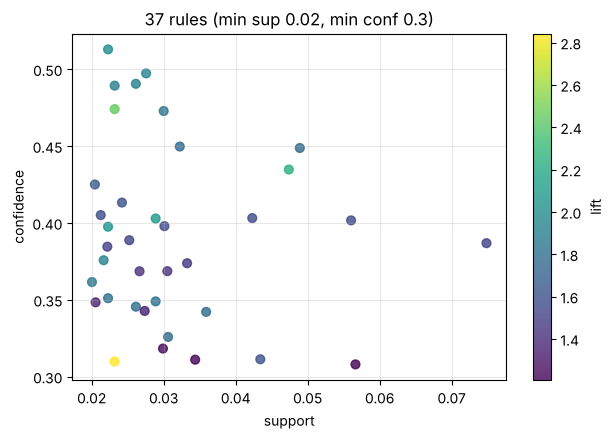

saved t11_rules.csv (37, 8)


In [12]:
if len(rules):
    plt.figure(figsize=(7, 4.5))
    sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=40, alpha=.8)
    plt.colorbar(sc, label="lift"); plt.xlabel("support"); plt.ylabel("confidence")
    plt.title(f"{len(rules)} rules (min sup {MIN_SUPPORT}, min conf {MIN_CONFIDENCE})"); plt.show()
    out = pretty(rules)
    out.to_csv("t11_rules.csv", index=False); print("saved t11_rules.csv", out.shape)